# Evaluating Classification

## Which messages should the filter hide?

A spam filter can hide a legitimate message or leave spam in the inbox. These are different mistakes. Here, spam is the positive class. A logistic model estimates spam probability from a synthetic count of promotional phrases between zero and ten.

The model is fitted once using training messages. The threshold control then changes how its fixed probabilities become actions on separate validation messages. A probability at or above the threshold sends a message to the spam filter.

<img src="https://raw.githubusercontent.com/sonamu-jun/introduction-to-ai-convergence/main/07-1_Classification/assets/05_confusion_matrix.png" alt="A confusion matrix counts correctly kept messages, false alarms, missed spam, and correctly filtered spam at threshold 0.50." width="640" style="max-width:100%;height:auto;">

A confusion matrix compares actual labels with predicted classes. Rows are actual classes and columns are predicted actions. True positives (TP) are spam caught; false positives (FP) are legitimate messages hidden by mistake. False negatives (FN) are spam missed; true negatives (TN) are legitimate messages kept correctly.


## Several ways to describe the same mistakes

Accuracy is the fraction of all messages classified correctly. When spam is rare, keeping every message can achieve high accuracy while catching no spam. The displayed spam count makes this class imbalance visible.

Precision asks how many messages classified as spam really are spam. Recall asks how much of the actual spam was caught. F1 is their harmonic mean; it is low when either precision or recall is low. F1 ignores true negatives and does not express every cost of a filtering mistake.

Raising the threshold generally filters fewer messages, reducing false alarms but potentially missing more spam. Precision need not improve at every step on a finite dataset. The matrix and all four scores are recomputed from the same predictions.

`Best F1` chooses from nineteen predefined thresholds using validation F1. It does not refit the model. A final performance report needs a separate test set after this choice is fixed.


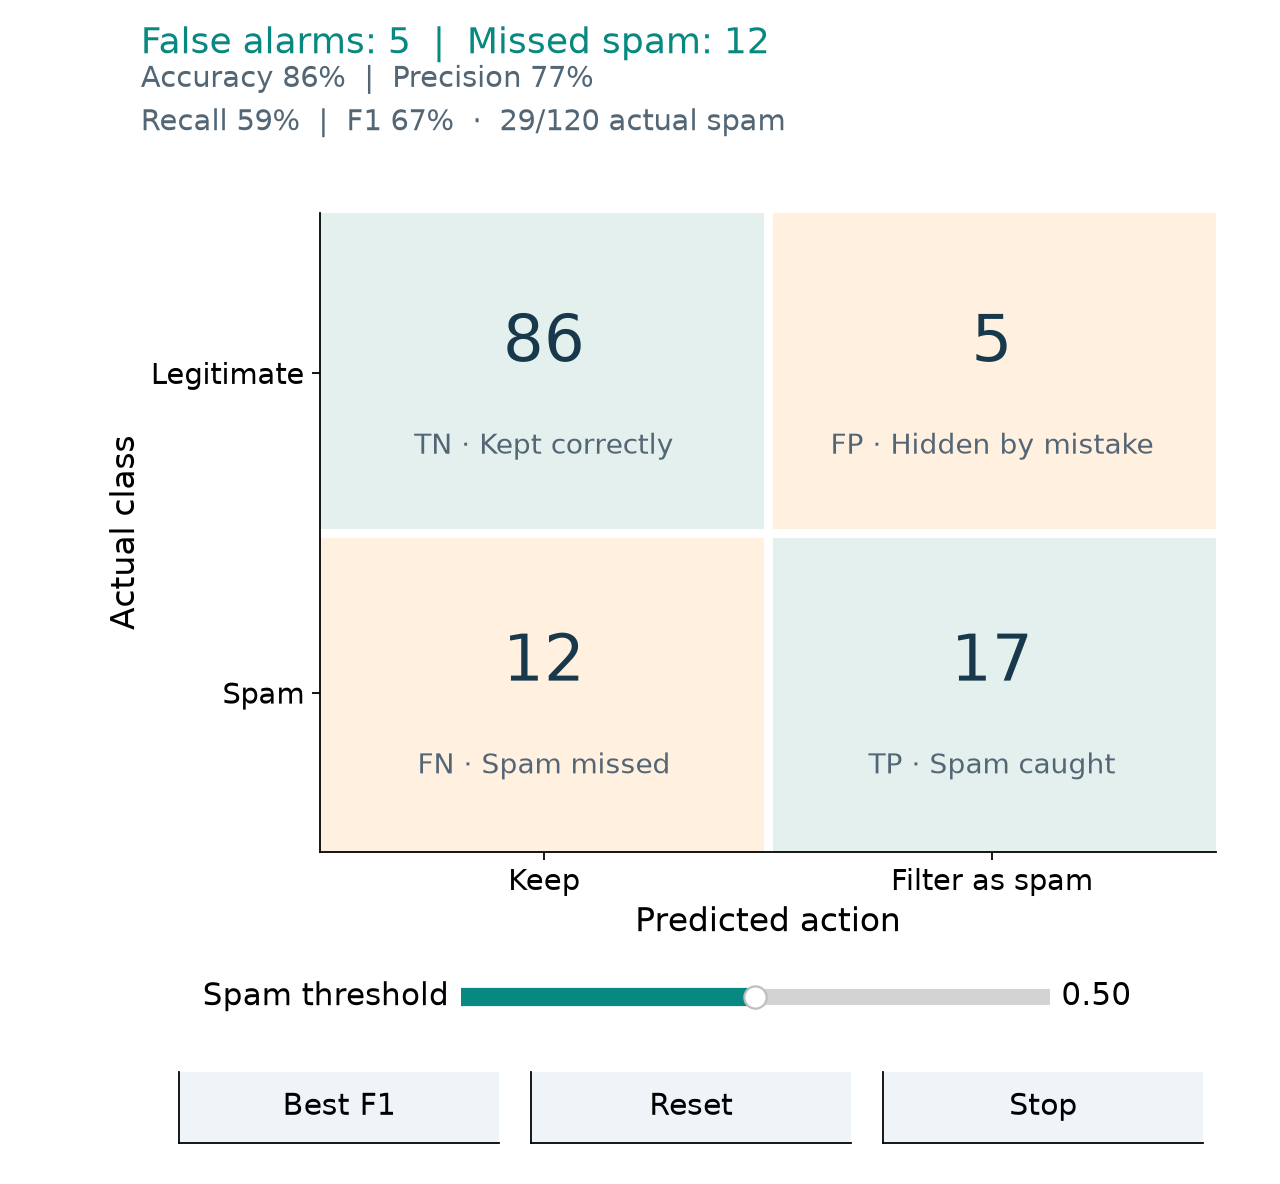

In [1]:
import os
import sys
import io
import numpy as np
import matplotlib

CLASSIFICATION_STATIC = os.environ.get("CLASSIFICATION_STATIC") == "1"
CLASSIFICATION_BROWSER = sys.platform == "emscripten"
if not CLASSIFICATION_STATIC and not CLASSIFICATION_BROWSER:
    from IPython import get_ipython
    shell = get_ipython()
    if shell is not None and getattr(shell, "kernel", None) is not None:
        shell.run_line_magic("matplotlib", "widget")

import matplotlib.pyplot as plt
from matplotlib.widgets import Slider, Button
from matplotlib.colors import ListedColormap
from IPython.display import Image, display
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier

plt.rcParams.update({
    "font.size": 15, "axes.labelsize": 15,
    "xtick.labelsize": 13, "ytick.labelsize": 13, "legend.fontsize": 12,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": .16, "lines.linewidth": 2.5,
    "axes.unicode_minus": False, "figure.facecolor": "white",
})
BLUE, TEAL, ORANGE, PURPLE = "#3268a8", "#078880", "#d87522", "#8251ac"


def sigmoid(score):
    score = np.clip(np.asarray(score, dtype=float), -500, 500)
    return 1 / (1 + np.exp(-score))


def softmax(scores):
    scores = np.asarray(scores, dtype=float)
    weights = np.exp(scores - scores.max(axis=-1, keepdims=True))
    return weights / weights.sum(axis=-1, keepdims=True)


def binary_loss(labels, scores):
    # The logaddexp form avoids taking log(0) at extreme scores.
    return float(np.mean(np.logaddexp(0, scores) - labels * scores))


def classification_metrics(observed, predicted):
    observed, predicted = np.asarray(observed), np.asarray(predicted)
    tp = int(np.sum((observed == 1) & (predicted == 1)))
    tn = int(np.sum((observed == 0) & (predicted == 0)))
    fp = int(np.sum((observed == 0) & (predicted == 1)))
    fn = int(np.sum((observed == 1) & (predicted == 0)))
    return {"TP": tp, "TN": tn, "FP": fp, "FN": fn,
            "accuracy": (tp + tn) / len(observed),
            "precision": tp / (tp + fp) if tp + fp else np.nan,
            "recall": tp / (tp + fn) if tp + fn else np.nan,
            "F1": 2 * tp / (2 * tp + fp + fn) if 2 * tp + fp + fn else np.nan}


def percent(value):
    return "undefined" if not np.isfinite(value) else f"{value:.0%}"


# A rerun releases the previous figure and its input callbacks first.
for _previous_view in globals().get("_classification_views", {}).values():
    _previous_view.close()
_classification_views = {}


class ClassificationExplorer:
    """One figure keeps the selected model, predictions and scores together."""

    def __init__(self, name, render, sliders, actions=()):
        self.render = render
        self.slider_specs = sliders
        self.controls, self.buttons, self.state = {}, {}, {}
        self.stopped = False
        self.defaults = {key: initial for key, label, low, high, initial, step, fmt in sliders}
        with plt.ioff():
            self.figure = plt.figure(figsize=(8, 8.0 if len(sliders) == 3 else 7.4), dpi=80)
        self.status = self.figure.text(.11, .955, "", fontsize=16, color=TEAL)
        self.detail = self.figure.text(.11, .89, "", fontsize=13, color="#536675", linespacing=1.5)
        bottom = .28 + .07 * (len(sliders) - 1)
        self.ax = self.figure.add_axes([.14, bottom, .81, .82 - bottom])
        for i, (key, label, low, high, initial, step, fmt) in enumerate(sliders):
            y = .145 + .07 * (len(sliders) - i - 1)
            slider = Slider(self.figure.add_axes([.36, y, .46, .026]),
                            label, low, high, valinit=initial, valstep=step,
                            valfmt=fmt, color=TEAL)
            slider.label.set_fontsize(14)
            slider.valtext.set_fontsize(14)
            slider.on_changed(self.update)
            self.controls[key] = slider
        commands = list(actions) + [("Reset", lambda view: view.reset()),
                                    ("Stop", lambda view: view.stop())]
        self.commands = commands
        width = min(.25, .83 / len(commands) - .025)
        for i, (label, callback) in enumerate(commands):
            button = Button(self.figure.add_axes([.14 + i * (width + .025), .035, width, .06]),
                            label, color="#eef4f7", hovercolor="#d7e9e6")
            button.label.set_fontsize(13.5)
            button.on_clicked(lambda event, cb=callback: cb(self) if not self.stopped else None)
            self.buttons[label] = button
        self.figure.canvas.mpl_connect("close_event", lambda event: self.stop())
        _classification_views[name] = self
        self.update()

    def update(self, _=None):
        if self.stopped:
            return
        self.ax.clear()
        self.state = self.render(self, **{key: slider.val for key, slider in self.controls.items()})
        self.figure.canvas.draw_idle()
        self.refresh_local()

    def set_values(self, **values):
        if self.stopped:
            return
        for key, value in values.items():
            slider = self.controls[key]
            events, drawing = slider.eventson, slider.drawon
            slider.eventson = slider.drawon = False
            slider.set_val(value)
            slider.eventson, slider.drawon = events, drawing
        self.update()

    def reset(self):
        self.set_values(**self.defaults)

    def refresh_local(self):
        if not hasattr(self, "local_image"):
            return
        from matplotlib.transforms import Bbox
        width, height = self.figure.get_size_inches()
        # Crop only the embedded Matplotlib controls; native widgets follow the chart.
        lower = max(0, self.ax.get_position().y0 - .09) * height
        buffer = io.BytesIO()
        self.figure.savefig(buffer, format="png", dpi=80, facecolor="white",
                            bbox_inches=Bbox.from_extents(0, lower, width, height))
        self.local_image.value = buffer.getvalue()
        self.syncing_local = True
        for key, control in self.local_controls.items():
            control.value = self.controls[key].val
        self.syncing_local = False

    def start_local(self):
        from ipywidgets import Image as WidgetImage, FloatSlider, IntSlider
        from ipywidgets import Button as WidgetButton, HBox, VBox, Layout
        self.syncing_local = False
        self.local_image = WidgetImage(format="png", layout=Layout(
            width="100%", max_width="640px", height="auto"))
        self.local_controls, self.local_buttons = {}, {}
        for key, label, low, high, initial, step, fmt in self.slider_specs:
            slider_type = IntSlider if fmt == "%0.0f" and step == 1 else FloatSlider
            control = slider_type(value=initial, min=low, max=high, step=step,
                                  description=label, readout_format=fmt.replace("%0", ""),
                                  continuous_update=True,
                                  style={"description_width": "120px"},
                                  layout=Layout(width="100%", max_width="640px"))
            def changed(change, key=key):
                if not self.syncing_local and not self.stopped:
                    self.controls[key].set_val(change["new"])
            control.observe(changed, names="value")
            self.local_controls[key] = control
        for label, callback in self.commands:
            button = WidgetButton(description=label, layout=Layout(
                flex="1 1 0", min_width="120px", height="34px", margin="2px"))
            button.on_click(lambda _, cb=callback: cb(self) if not self.stopped else None)
            self.local_buttons[label] = button
        row = HBox(list(self.local_buttons.values()), layout=Layout(width="100%", flex_flow="row wrap"))
        self.local_row = row
        self.local_output = VBox([self.local_image, *self.local_controls.values(), row],
                                layout=Layout(width="100%", max_width="640px"))
        self.refresh_local()
        display(self.local_output)

    def start(self):
        if CLASSIFICATION_STATIC:
            buffer = io.BytesIO()
            self.figure.savefig(buffer, format="png", dpi=160, facecolor="white")
            display(Image(data=buffer.getvalue(), width=640,
                          alt=self.status.get_text() + ". " + self.detail.get_text()))
            plt.close(self.figure)
        elif CLASSIFICATION_BROWSER:
            # JSPCV sends mouse events after this cell has returned.
            plt.show(block=False)
        elif hasattr(self.figure.canvas, "toolbar_visible"):
            # The ipympl figure supplies a responsive chart with native widget controls.
            self.start_local()
        else:
            plt.show(block=False)

    def stop(self):
        if self.stopped:
            return
        self.stopped = True
        for control in list(self.controls.values()) + list(self.buttons.values()):
            control.set_active(False)
        for control in [*getattr(self, "local_controls", {}).values(),
                        *getattr(self, "local_buttons", {}).values()]:
            control.disabled = True
        if hasattr(self, "local_buttons"):
            self.local_buttons["Stop"].description = "Stopped"
        self.buttons["Stop"].label.set_text("Stopped")
        self.figure.canvas.draw_idle()

    def close(self):
        self.stop()
        for control in list(self.controls.values()) + list(self.buttons.values()):
            control.disconnect_events()
        plt.close(self.figure)
        if hasattr(self, "local_output"):
            self.local_output.close()
            self.local_image.close()
            self.local_row.close()
            for control in [*self.local_controls.values(), *self.local_buttons.values()]:
                control.close()

rng = np.random.default_rng(73)
promotion = rng.integers(0, 11, 360)
spam = rng.binomial(1, sigmoid(.85 * promotion - 7))
train_id, validation_id = train_test_split(np.arange(len(spam)), test_size=1/3,
                                         stratify=spam, random_state=73)
feature_mean, feature_scale = promotion[train_id].mean(), promotion[train_id].std()


def message_features(values):
    values = np.atleast_1d(values)
    return np.column_stack([np.ones(len(values)), (values - feature_mean) / feature_scale])


train_features = message_features(promotion[train_id])
coefficients = np.zeros(2)
for iteration in range(1200):
    probability = sigmoid(train_features @ coefficients)
    coefficients -= .15 * train_features.T @ (probability - spam[train_id]) / len(train_id)
validation_probability = sigmoid(message_features(promotion[validation_id]) @ coefficients)
candidate_thresholds = np.linspace(.05, .95, 19)
candidate_f1 = [classification_metrics(spam[validation_id], validation_probability >= threshold)["F1"]
                for threshold in candidate_thresholds]
# Ties favor the first (lower) threshold in the fixed list.
best_threshold = float(candidate_thresholds[int(np.nanargmax(candidate_f1))])


def render_messages(view, threshold):
    predicted = (validation_probability >= threshold).astype(int)
    result = classification_metrics(spam[validation_id], predicted)
    matrix = np.array([[result["TN"], result["FP"]], [result["FN"], result["TP"]]])
    ax = view.ax
    ax.set_position([.25, .28, .70, .54])
    ax.grid(False)
    ax.imshow([[0, 1], [1, 0]], cmap=ListedColormap(["#e3f0ee", "#fff0df"]), vmin=0, vmax=1,
              extent=(-.5, 1.5, 1.5, -.5), aspect="auto")
    descriptions = [["TN · Kept correctly", "FP · Hidden by mistake"],
                    ["FN · Spam missed", "TP · Spam caught"]]
    for row in range(2):
        for col in range(2):
            ax.text(col, row-.09, str(matrix[row, col]), ha="center", va="center",
                    fontsize=29, color="#17394b")
            ax.text(col, row+.23, descriptions[row][col], ha="center", va="center",
                    fontsize=12.5, color="#536675")
    ax.axhline(.5, color="white", linewidth=4)
    ax.axvline(.5, color="white", linewidth=4)
    ax.set(xticks=[0, 1], xticklabels=["Keep", "Filter as spam"],
           yticks=[0, 1], yticklabels=["Legitimate", "Spam"],
           xlabel="Predicted action", ylabel="Actual class")
    total, positives = len(validation_id), int(spam[validation_id].sum())
    view.status.set_text(f"False alarms: {result['FP']}  |  Missed spam: {result['FN']}")
    view.detail.set_text(f"Accuracy {percent(result['accuracy'])}  |  Precision {percent(result['precision'])}\n"
                         f"Recall {percent(result['recall'])}  |  F1 {percent(result['F1'])}  ·  {positives}/{total} actual spam")
    return {"prediction": predicted, "metrics": result, "matrix": matrix,
            "probability": validation_probability.copy()}


spam_demo = ClassificationExplorer("spam", render_messages, [
    ("threshold", "Spam threshold", 0, 1, .5, .01, "%0.2f"),
], actions=[("Best F1", lambda view: view.set_values(threshold=best_threshold))])
spam_demo.start()


## A score needs a denominator and a context

At threshold one, this model filters no messages. Precision is then undefined because there are no predicted positives; the screen says so. Recall and F1 are zero because actual spam is present and none is caught. At threshold zero, every message is filtered: recall reaches one, but legitimate messages are also hidden.

Cross-entropy evaluates probabilities, while accuracy, precision, recall, and F1 here evaluate thresholded decisions. Moving the threshold can change these four scores without changing cross-entropy. A well-ranked set of messages also need not have calibrated probabilities.

A useful threshold depends on how costly each mistake is. New spam patterns or a changed proportion of spam can alter performance. In multiclass problems, a confusion matrix has one row and column per class; class-specific scores or a macro average can expose mistakes hidden by overall accuracy.
